<a href="https://colab.research.google.com/github/PavloBachysh/pattern-recognition-practice/blob/main/classification-mini-project/notebooks/PR04_Bachysh_Pavlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 4
## Мініпроєкт «Порівняння класичних моделей класифікації»
**Дисципліна:** Розпізнавання образів і машинне навчання
**Студент:** Бачиш Павло
**Група:** ІН-42\2
**Дата виконання:** 01.10.2026
### Мета роботи
Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати класичні
алгоритми класифікації, налаштовувати їхні основні гіперпараметри та коректно порівнювати
моделі за однаковими умовами без використання тестової вибірки для підбору рішень.

Об'єктом дослідження в цій роботі є медичні показники та стан пацієнта. Використовується багато різних числових і категоріальних ознак (так як вік, зріст, тиск і т.д). Цільова змінна - *target*. Всього потрібно розпізнати 2 класи (задача бінарної класифікації).

Позитивний клас - 1 (хворий)

Негативний клас - 0 (здоровий)

Практичною метою класифікації є виявлення чи пацієнт здоровий чи хворий. Саме тому для цієї задачі найважливішою метрикою є **Recall**. Найбільш важливим є те, щоб всі хворі пацієнти були виявлені.


##Підготовка до роботи

In [27]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
 accuracy_score,
 precision_score,
 recall_score,
 f1_score,
 ConfusionMatrixDisplay
)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project")
DATA_DIR = PROJECT_DIR / "data"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOKS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("Робоча папка:", PROJECT_DIR)
print("Папка даних:", DATA_DIR)
print("Папка Notebook:", NOTEBOOKS_DIR)
print("Папка звітів:", REPORTS_DIR)

Робоча папка: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project
Папка даних: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data
Папка Notebook: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/notebooks
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports


#ЧАСТИНА I. ПРАКТИЧНА РОБОТА 4
##Підготовка даних, Pipeline і логістична регресія**


In [4]:
dirty_data_df = pd.read_csv(DATA_DIR / "heart_disease.csv")

In [5]:
display(dirty_data_df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [6]:
print("Розмір таблиці:", dirty_data_df.shape)
print("Кількість рядків:", dirty_data_df.shape[0])
print("Кількість стовпців:", dirty_data_df.shape[1])
print("Кількість дублікатів:", dirty_data_df.duplicated().sum())
print("Кількість пропущених значень:", dirty_data_df.isna().sum().sum())
print("Кількість класів (очікувано 2):", dirty_data_df["target"].nunique())
print("Класи (очікувано 0 і 1):", dirty_data_df["target"].unique())
print("Розподіл класів (очікувано +- порівну):", dirty_data_df["target"].value_counts())
print("Стовпці:", dirty_data_df.keys())
print("Типи даних:\n", dirty_data_df.dtypes)

Розмір таблиці: (303, 14)
Кількість рядків: 303
Кількість стовпців: 14
Кількість дублікатів: 0
Кількість пропущених значень: 6
Кількість класів (очікувано 2): 2
Класи (очікувано 0 і 1): [0 1]
Розподіл класів (очікувано +- порівну): target
0    164
1    139
Name: count, dtype: int64
Стовпці: Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')
Типи даних:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


Кількість об’єктів *303*

Кількість вхідних ознак *13*

Числові ознаки *age, trestbps, chol, thalach, oldpeak*

Категоріальні ознаки *sex, cp, fbs, restecg, exang, slope, ca, thal*

Кількість пропусків *6*

Кількість класів *2*

Позитивний клас *1*

In [29]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = dirty_data_df[numeric_columns + categorical_columns]
y = dirty_data_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
numeric_pipeline_no_scaler = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", "passthrough")
])

categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(
handle_unknown="ignore",
sparse_output=False
))
])
preprocessor = ColumnTransformer([
("num", numeric_pipeline, numeric_columns),
("cat", categorical_pipeline, categorical_columns)
])
preprocessor_no_scaler = ColumnTransformer([
("num", numeric_pipeline_no_scaler, numeric_columns),
("cat", categorical_pipeline, categorical_columns)
])
model_pipeline = Pipeline([
("preprocessor", preprocessor),
("classifier", LogisticRegression(max_iter=2000))
])
model_pipeline_no_scaler = Pipeline([
("preprocessor", preprocessor_no_scaler),
("classifier", LogisticRegression(max_iter=2000))
])



In [30]:
cv = StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)


In [35]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results = cross_validate(
    model_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)
cv_results_no_scaler = cross_validate(
    model_pipeline_no_scaler, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False
)

print("З маштабуанням")
for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} (+/- {std_score:.4f})")

print("\nБез маштабуання")
for metric in scoring:
    mean_score = cv_results_no_scaler[f"test_{metric}"].mean()
    std_score = cv_results_no_scaler[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} (+/- {std_score:.4f})")



З маштабуанням
accuracy: 0.8471 (+/- 0.0100)
precision: 0.8768 (+/- 0.0542)
recall: 0.7834 (+/- 0.0459)
f1: 0.8245 (+/- 0.0069)
roc_auc: 0.9025 (+/- 0.0144)

Без маштабуання
accuracy: 0.8471 (+/- 0.0100)
precision: 0.8768 (+/- 0.0542)
recall: 0.7834 (+/- 0.0459)
f1: 0.8245 (+/- 0.0069)
roc_auc: 0.8997 (+/- 0.0157)


In [38]:
import warnings
from sklearn.exceptions import ConvergenceWarning

rows = []
for label, pipe, cv_res in [
    ("З масштабуванням (StandardScaler)", model_pipeline, cv_results),
    ("Без масштабування (passthrough)", model_pipeline_no_scaler, cv_results_no_scaler),
]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", category=ConvergenceWarning)
        pipe.fit(X_train, y_train)

    clf = pipe.named_steps["classifier"]
    n_iter = int(clf.n_iter_.max())
    n_conv_warnings = sum(1 for w in caught if issubclass(w.category, ConvergenceWarning))

    rows.append({
        "Варіант": label,
        "F1 (mean)": round(float(cv_res["test_f1"].mean()), 4),
        "F1 (std)": round(float(cv_res["test_f1"].std()), 4),
        "ROC AUC (mean)": round(float(cv_res["test_roc_auc"].mean()), 4),
        "ROC AUC (std)": round(float(cv_res["test_roc_auc"].std()), 4),
        "Ітерацій (n_iter_)": n_iter,
        "Попереджень збіжності": n_conv_warnings,
    })

summary_13_1 = pd.DataFrame(rows)
print("\n=== Зведена таблиця до 13.1 ===")
print("(З використанням ШІ)")
print(summary_13_1.to_string(index=False))


=== Зведена таблиця до 13.1 ===
(З використанням ШІ)
                          Варіант  F1 (mean)  F1 (std)  ROC AUC (mean)  ROC AUC (std)  Ітерацій (n_iter_)  Попереджень збіжності
З масштабуванням (StandardScaler)     0.8245    0.0069          0.9025         0.0144                  18                      0
  Без масштабування (passthrough)     0.8245    0.0069          0.8997         0.0157                1238                      0


=== Результати CV для L1 і L2 при різних C ===
penalty    solver      C  mean_cv_roc_auc  std_cv_roc_auc  mean_cv_f1  std_cv_f1
     l1 liblinear   0.01           0.5000          0.0000      0.0000     0.0000
     l1 liblinear   0.10           0.8844          0.0260      0.7926     0.0306
     l1 liblinear   1.00           0.9070          0.0114      0.8123     0.0173
     l1 liblinear  10.00           0.9019          0.0105      0.8321     0.0108
     l1 liblinear 100.00           0.8974          0.0122      0.8363     0.0127
     l2     lbfgs   0.01           0.8893          0.0347      0.7658     0.0171
     l2     lbfgs   0.10           0.9025          0.0166      0.8140     0.0299
     l2     lbfgs   1.00           0.9025          0.0144      0.8245     0.0069
     l2     lbfgs  10.00           0.8995          0.0137      0.8363     0.0127
     l2     lbfgs 100.00           0.8977          0.0121      0.8363     0.0127

Найкраща конфігурація за CV: {'classifier__C': 10, 'classifie

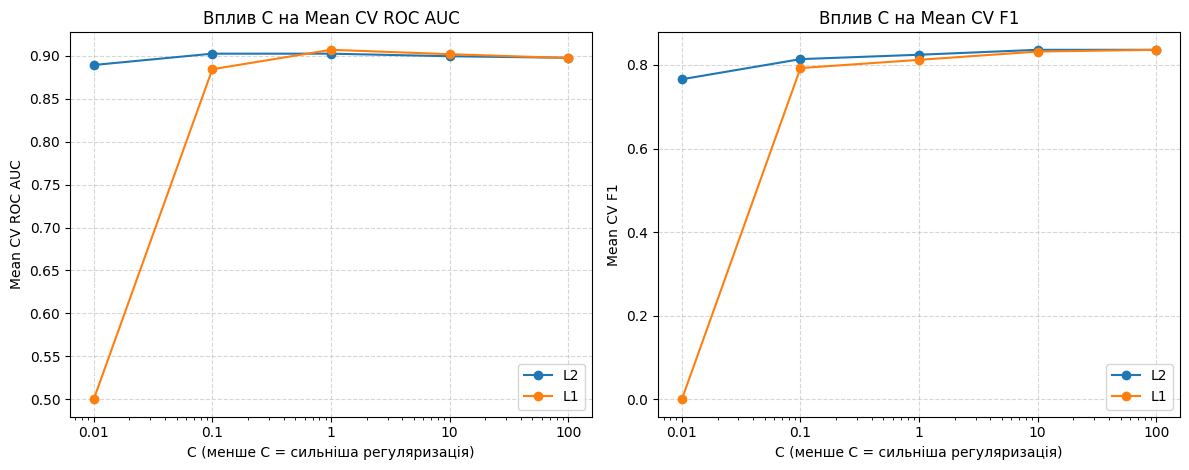

In [44]:
from sklearn.model_selection import GridSearchCV

c_values = [0.01, 0.1, 1, 10, 100]

reg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42)),
])

param_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__C": c_values,
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__solver": ["liblinear"],
        "classifier__C": c_values,
    },
]

grid_search = GridSearchCV(
    estimator=reg_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "f1": "f1"},
    refit="f1",
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

# Охайна таблиця результатів CV для всіх комбінацій penalty та C
cv_reg_df = pd.DataFrame({
    "penalty": grid_search.cv_results_["param_classifier__penalty"],
    "solver": grid_search.cv_results_["param_classifier__solver"],
    "C": grid_search.cv_results_["param_classifier__C"].astype(float),
    "mean_cv_roc_auc": grid_search.cv_results_["mean_test_roc_auc"].round(4),
    "std_cv_roc_auc": grid_search.cv_results_["std_test_roc_auc"].round(4),
    "mean_cv_f1": grid_search.cv_results_["mean_test_f1"].round(4),
    "std_cv_f1": grid_search.cv_results_["std_test_f1"].round(4),
}).sort_values(["penalty", "C"]).reset_index(drop=True)

print("=== Результати CV для L1 і L2 при різних C ===")
print(cv_reg_df.to_string(index=False))

print("\nНайкраща конфігурація за CV:", grid_search.best_params_)
print(f"Найкращий середній CV F1: {grid_search.best_score_:.4f}")

# Графік впливу C на середню CV ROC AUC та середню CV F1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

metrics_to_plot = [
    ("mean_cv_roc_auc", "Mean CV ROC AUC"),
    ("mean_cv_f1", "Mean CV F1"),
]

for ax, (col_name, y_label) in zip(axes, metrics_to_plot):
    for pen in ["l2", "l1"]:
        sub = cv_reg_df[cv_reg_df["penalty"] == pen].sort_values("C")
        ax.plot(
            sub["C"],
            sub[col_name],
            marker="o",
            label=pen.upper(),
        )
    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([str(c) for c in c_values])
    ax.set_xlabel("C (менше C = сильніша регуляризація)")
    ax.set_ylabel(y_label)
    ax.set_title(f"Вплив C на {y_label}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

=== Результати CV для L1 і L2 при різних C ===
penalty    solver    C  mean_cv_roc_auc  std_cv_roc_auc  mean_cv_f1  std_cv_f1
     l1 liblinear  1.0           0.9070          0.0114      0.8123     0.0173
     l1 liblinear  2.0           0.9039          0.0119      0.8220     0.0123
     l1 liblinear  3.0           0.9033          0.0112      0.8329     0.0188
     l1 liblinear  4.0           0.9040          0.0112      0.8277     0.0231
     l1 liblinear  5.0           0.9030          0.0112      0.8335     0.0186
     l1 liblinear  6.0           0.9019          0.0106      0.8335     0.0186
     l1 liblinear  7.0           0.9019          0.0106      0.8371     0.0125
     l1 liblinear  8.0           0.9019          0.0096      0.8321     0.0108
     l1 liblinear  9.0           0.9016          0.0103      0.8321     0.0108
     l1 liblinear 10.0           0.9019          0.0105      0.8321     0.0108
     l2     lbfgs  1.0           0.9025          0.0144      0.8245     0.0069
     

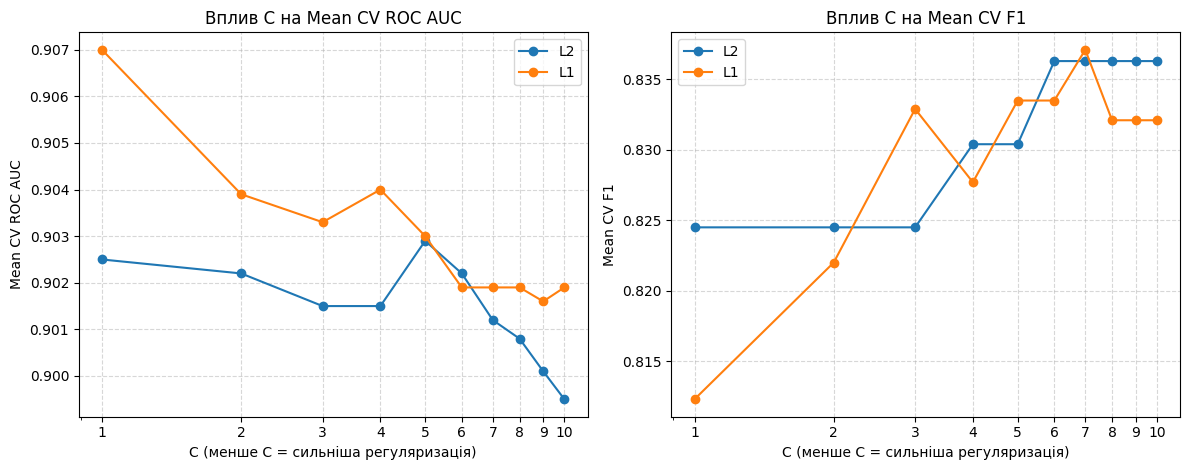

In [43]:
c_values = list(range(1,11))

param_grid = [
    {
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__C": c_values,
    },
    {
        "classifier__penalty": ["l1"],
        "classifier__solver": ["liblinear"],
        "classifier__C": c_values,
    },
]

grid_search = GridSearchCV(
    estimator=reg_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "f1": "f1"},
    refit="f1",
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

# Охайна таблиця результатів CV для всіх комбінацій penalty та C
cv_reg_df = pd.DataFrame({
    "penalty": grid_search.cv_results_["param_classifier__penalty"],
    "solver": grid_search.cv_results_["param_classifier__solver"],
    "C": grid_search.cv_results_["param_classifier__C"].astype(float),
    "mean_cv_roc_auc": grid_search.cv_results_["mean_test_roc_auc"].round(4),
    "std_cv_roc_auc": grid_search.cv_results_["std_test_roc_auc"].round(4),
    "mean_cv_f1": grid_search.cv_results_["mean_test_f1"].round(4),
    "std_cv_f1": grid_search.cv_results_["std_test_f1"].round(4),
}).sort_values(["penalty", "C"]).reset_index(drop=True)

print("=== Результати CV для L1 і L2 при різних C ===")
print(cv_reg_df.to_string(index=False))

print("\nНайкраща конфігурація за CV:", grid_search.best_params_)
print(f"Найкращий середній CV F1: {grid_search.best_score_:.4f}")

# Графік впливу C на середню CV ROC AUC та середню CV F1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

metrics_to_plot = [
    ("mean_cv_roc_auc", "Mean CV ROC AUC"),
    ("mean_cv_f1", "Mean CV F1"),
]

for ax, (col_name, y_label) in zip(axes, metrics_to_plot):
    for pen in ["l2", "l1"]:
        sub = cv_reg_df[cv_reg_df["penalty"] == pen].sort_values("C")
        ax.plot(
            sub["C"],
            sub[col_name],
            marker="o",
            label=pen.upper(),
        )
    ax.set_xscale("log")
    ax.set_xticks(c_values)
    ax.set_xticklabels([str(c) for c in c_values])
    ax.set_xlabel("C (менше C = сильніша регуляризація)")
    ax.set_ylabel(y_label)
    ax.set_title(f"Вплив C на {y_label}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()


В рзультаті пдбору, маємо найкращий результат за С=7 при регуляризації Л1

Найкраща конфігурація за CV: {'classifier__C': 7, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Найкращий середній CV F1: 0.8371

In [45]:
# 1. Збираємо та навчаємо найкращий пайплайн за CV на тренувальній вибірці
best_model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            C=7,
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=42,
        ),
    ),
])

best_model_pipeline.fit(X_train, y_train)

# 2. Отримуємо назви всіх ознак після OneHotEncoder та ColumnTransformer
fitted_preprocessor = best_model_pipeline.named_steps["preprocessor"]
fitted_classifier = best_model_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefs = fitted_classifier.coef_[0]

# 3. Формуємо таблицю коефіцієнтів та їхніх модулів
coef_df = (
    pd.DataFrame({
        "feature": feature_names,
        "coef": coefs,
        "abs_coef": np.abs(coefs),
        "effect_on_log_odds": np.where(
            coefs > 0,
            "збільшує (+)",
            np.where(coefs < 0, "зменшує (-)", "0.0 (занулено L1)"),
        ),
    })
    .sort_values("abs_coef", ascending=False)
    .reset_index(drop=True)
)

print("=== Усі ознаки, відсортовані за модулем коефіцієнта ===")
print(coef_df.to_string(index=False))

top5_features = coef_df.head(5)
print("\n=== Топ-5 ознак із найбільшими за модулем коефіцієнтами ===")
print(top5_features.to_string(index=False))

zeroed_count = int((coef_df["coef"] == 0).sum())
print(f"\nКількість занулених коефіцієнтів (L1): {zeroed_count} із {len(coef_df)}")

=== Усі ознаки, відсортовані за модулем коефіцієнта ===
         feature      coef  abs_coef effect_on_log_odds
     cat__ca_0.0 -2.171002  2.171002        зменшує (-)
   cat__thal_7.0  1.468012  1.468012       збільшує (+)
     cat__cp_4.0  1.327758  1.327758       збільшує (+)
    cat__sex_0.0 -1.292649  1.292649        зменшує (-)
  cat__slope_2.0  1.022705  1.022705       збільшує (+)
     cat__cp_1.0 -0.715867  0.715867        зменшує (-)
     cat__cp_3.0 -0.529091  0.529091        зменшує (-)
     cat__ca_2.0  0.512481  0.512481       збільшує (+)
  cat__exang_0.0 -0.467150  0.467150        зменшує (-)
     cat__ca_3.0  0.435366  0.435366       збільшує (+)
     cat__cp_2.0  0.419305  0.419305       збільшує (+)
   num__trestbps  0.415355  0.415355       збільшує (+)
    num__thalach -0.381193  0.381193        зменшує (-)
    cat__sex_1.0  0.377177  0.377177       збільшує (+)
cat__restecg_2.0  0.366253  0.366253       збільшує (+)
  cat__slope_1.0 -0.305601  0.305601        змен